In [39]:
import os
import numpy as np
import pandas as pd
import joblib
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, mean_absolute_error



In [2]:
velocity_rpe_df = pd.read_csv("./data/deadlift_velocity_rpe.csv")

In [3]:
velocity_rpe_df.describe()

,mean_velocity_ms
count,5000.000000
mean,0.485412
std,0.195658
min,0.080000
25%,0.350000
50%,0.460000
75%,0.600000
max,1.150000


In [4]:
velocity_rpe_df.sample(10)

,mean_velocity_ms,rpe
3124,0.53,7
3480,0.43,8
2442,0.43,7
1880,0.73,6
517,0.68,6
750,0.57,6
234,0.49,<5
1745,0.26,9
491,0.57,6
2618,0.36,9


In [5]:
%matplotlib inline

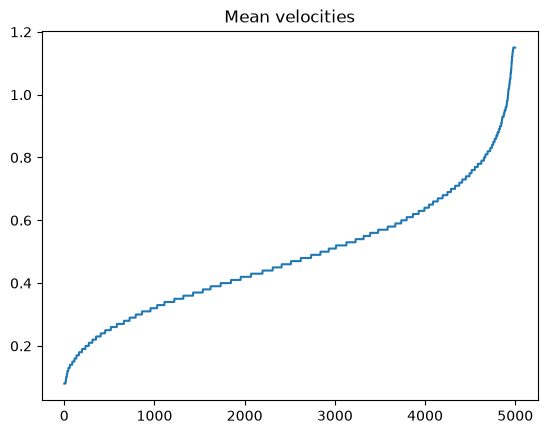

In [6]:
plt.plot(velocity_rpe_df.mean_velocity_ms.sort_values().values)
plt.title("Mean velocities")
plt.show()

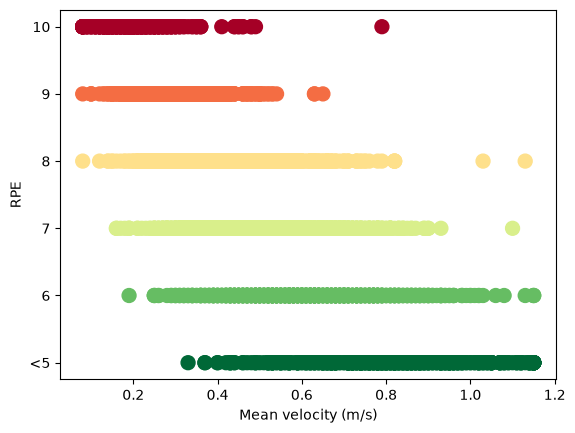

In [7]:
order = ["<5", "6", "7", "8", "9", "10"]
y = velocity_rpe_df.rpe.map({k: i for i, k in enumerate(order)})

plt.scatter(velocity_rpe_df.mean_velocity_ms, y, c=y, cmap="RdYlGn_r", s=100)
plt.yticks(range(len(order)), order)
plt.xlabel("Mean velocity (m/s)")
plt.ylabel("RPE")
plt.show()

In [8]:
#mean_velocity_rpe_decision_tree = DecisionTreeClassifier()
#mean_velocity_rpe_decision_tree.fit(velocity_rpe_df.mean_velocity_ms, y)
df = velocity_rpe_df.copy()
df["rpe_idx"] = df.rpe.map({k: i for i, k in enumerate(order)})

features = ["mean_velocity_ms"]
X, y = df[features], df["rpe_idx"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



In [9]:
model_mean_velocity_rpe = DecisionTreeClassifier(random_state=42 * 67 * 69)
model_mean_velocity_rpe.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",194166
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sam

In [10]:
pred = model_mean_velocity_rpe.predict(X_test)
print(classification_report(y_test, pred, labels=range(len(order)), target_names=order, zero_division=0))
print(confusion_matrix(y_test, pred, labels=range(len(order))))

              precision    recall  f1-score   support

          <5       0.55      0.39      0.46        76
           6       0.44      0.42      0.43       214
           7       0.42      0.52      0.47       288
           8       0.43      0.40      0.41       249
           9       0.36      0.25      0.30       114
          10       0.61      0.71      0.66        59

    accuracy                           0.44      1000
   macro avg       0.47      0.45      0.45      1000
weighted avg       0.44      0.44      0.44      1000

[[ 30  38   7   1   0   0]
 [ 20  90  87  16   1   0]
 [  3  62 151  60   9   3]
 [  2  13 100  99  31   4]
 [  0   0  16  49  29  20]
 [  0   1   0   6  10  42]]


In [11]:
def visualize_predictions(velocity, actual, predicted):
    order = ["<5", "6", "7", "8", "9", "10"]
    idx = np.argsort(np.asarray(velocity))
    v = np.asarray(velocity)[idx]
    a = np.asarray(actual)[idx]
    p = np.asarray(predicted)[idx]

    plt.scatter(v, a, c=a, cmap="RdYlGn_r", s=100, alpha=0.4, label="actual")
    plt.step(v, p, where="mid", color="k", lw=2, label="model prediction")
    plt.yticks(range(len(order)), order)
    plt.xlabel("Mean velocity (m/s)")
    plt.ylabel("RPE")
    plt.legend()
    plt.show()


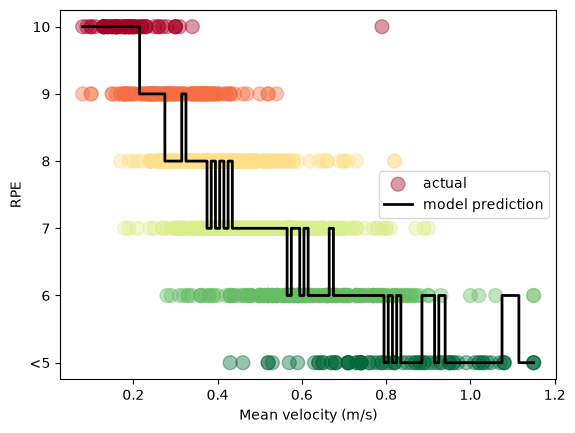

In [12]:
visualize_predictions(X_test.mean_velocity_ms, y_test, pred)

In [13]:
model_mean_velocity_rpe.predict([[0.34]])

/data/projects/fullsterkur-ai/lift-analyzer-tool/.venv/lib/python3.12/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


array([3])

The classification model with mean velocity -> RPE works well in this example.

However, in real life, RPE doesn't just correlate to mean velocity only.

For the next step, I would try doing predictions with peak velocity aswell. Now the question would be, how is peak velocity helpful here. Usually, peak velocity correlated with average velocity.. if it's a smooth lift. However, sticking points would cause the average velocity to drop significantly, while the lifter can still carry a higher peak velocity after passing that sticking point. This is a good discussion to have, but let's rather start with visualizing first.

In [15]:
mean_peak_rpe_df = pd.read_csv("./data/deadlift_mean_peak_rpe.csv")

In [16]:
mean_peak_rpe_df.describe()

,mean_velocity_ms,peak_velocity_ms
count,5142.000000,5142.000000
mean,0.459426,0.724331
std,0.193045,0.316982
min,-0.031990,0.067637
25%,0.320000,0.500000
50%,0.440000,0.690000
75%,0.570000,0.900000
max,1.150000,2.600000


In [17]:
mean_peak_rpe_df.sample(10)

,mean_velocity_ms,peak_velocity_ms,rpe
4737,0.550000,0.850000,8
2415,0.450000,0.600000,6
5045,0.107107,0.297986,<5
339,0.480000,0.780000,7
2907,0.700000,0.810000,7
2225,0.320000,0.550000,10
1386,0.510000,0.710000,8
926,0.230000,0.510000,9
706,0.450000,0.780000,7
4983,0.560000,0.990000,6


In [18]:
mean_peak_y = mean_peak_rpe_df.rpe.map({k: i for i, k in enumerate(order)})


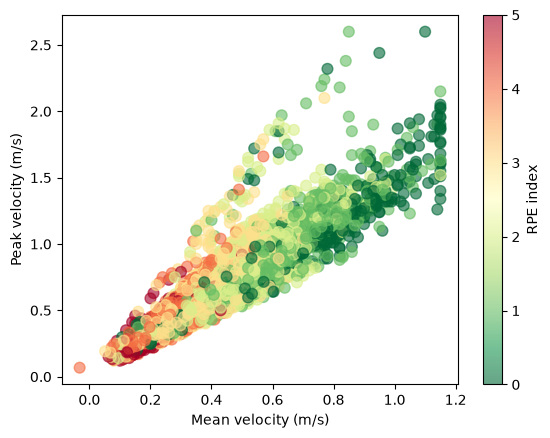

In [19]:
plt.scatter(mean_peak_rpe_df.mean_velocity_ms,
            mean_peak_rpe_df.peak_velocity_ms,
            c=mean_peak_y, cmap="RdYlGn_r", s=60, alpha=0.6)
plt.colorbar(label="RPE index")
plt.xlabel("Mean velocity (m/s)")
plt.ylabel("Peak velocity (m/s)")
plt.show()

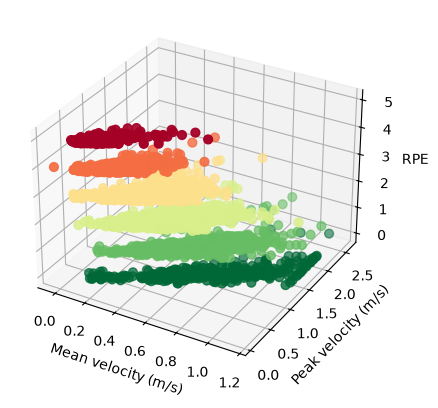

In [20]:
fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.scatter(mean_peak_rpe_df.mean_velocity_ms,
           mean_peak_rpe_df.peak_velocity_ms,
           mean_peak_y, c=mean_peak_y, cmap="RdYlGn_r", s=40)
ax.set_xlabel("Mean velocity (m/s)")
ax.set_ylabel("Peak velocity (m/s)")
ax.set_zlabel("RPE")
plt.show()


In [21]:
df = mean_peak_rpe_df.copy()
df["rpe_idx"] = df.rpe.map({k: i for i, k in enumerate(order)})
df["peak_mean_ratio"] = df["mean_velocity_ms"] / df["peak_velocity_ms"]



In [22]:
df

,mean_velocity_ms,peak_velocity_ms,rpe,rpe_idx,peak_mean_ratio
0,0.630000,1.010000,7,2,0.623762
1,0.450000,0.620000,8,3,0.725806
2,0.460000,0.550000,8,3,0.836364
3,0.520000,0.830000,8,3,0.626506
4,0.150000,0.250000,9,4,0.600000
...,...,...,...,...,...
5137,0.130034,0.333431,9,4,0.389988
5138,0.123358,0.182729,10,5,0.675087
5139,0.285099,0.407794,8,3,0.699127
5140,0.051486,0.191305,8,3,0.269128


In [23]:
features = ["mean_velocity_ms", "peak_velocity_ms"]
X, y = df[features], df["rpe_idx"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


In [24]:
mean_peak_model = RandomForestClassifier(random_state=42 * 67 * 69)
mean_peak_model.fit(X, y)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",194166
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap boo

In [25]:
pred = mean_peak_model.predict(X_test)
print(classification_report(y_test, pred, labels=range(len(order)), target_names=order, zero_division=0))
print(confusion_matrix(y_test, pred, labels=range(len(order))))

              precision    recall  f1-score   support

          <5       0.94      0.79      0.86        78
           6       0.75      0.70      0.72       177
           7       0.71      0.69      0.70       285
           8       0.69      0.79      0.73       268
           9       0.71      0.66      0.68       146
          10       0.75      0.75      0.75        75

    accuracy                           0.73      1029
   macro avg       0.76      0.73      0.74      1029
weighted avg       0.73      0.73      0.73      1029

[[ 62   7   6   2   1   0]
 [  1 124  36  15   0   1]
 [  3  30 198  44   9   1]
 [  0   3  34 211  14   6]
 [  0   2   5  32  96  11]
 [  0   0   0   4  15  56]]


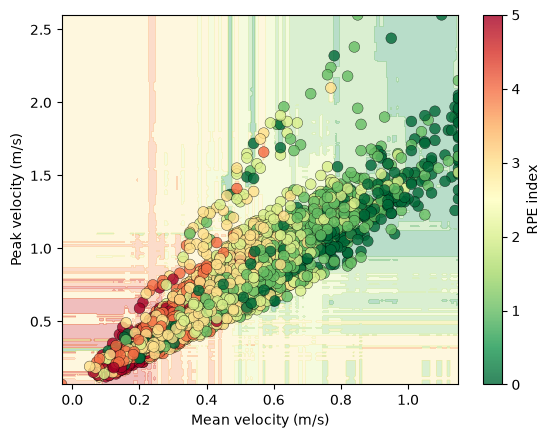

In [26]:
x = mean_peak_rpe_df.mean_velocity_ms
y = mean_peak_rpe_df.peak_velocity_ms

xx, yy = np.meshgrid(np.linspace(x.min(), x.max(), 300),
                     np.linspace(y.min(), y.max(), 300))
grid = pd.DataFrame({"mean_velocity_ms": xx.ravel(), "peak_velocity_ms": yy.ravel()})
zz = mean_peak_model.predict(grid).reshape(xx.shape)

plt.contourf(xx, yy, zz, levels=np.arange(-0.5, 6.5, 1), cmap="RdYlGn_r", alpha=0.3)
plt.scatter(x, y, c=mean_peak_y, cmap="RdYlGn_r", s=60, alpha=0.8, edgecolor="k", linewidth=0.3)
plt.colorbar(label="RPE index")
plt.xlabel("Mean velocity (m/s)")
plt.ylabel("Peak velocity (m/s)")
plt.show()

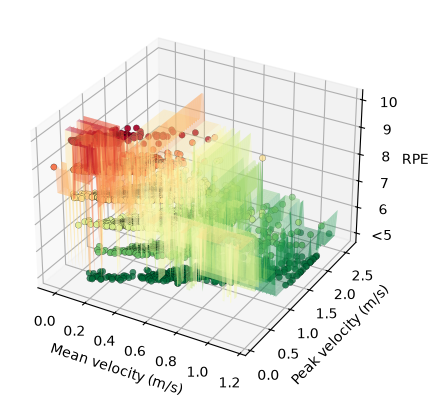

In [27]:
x = mean_peak_rpe_df.mean_velocity_ms
y = mean_peak_rpe_df.peak_velocity_ms

xx, yy = np.meshgrid(np.linspace(x.min(), x.max(), 100),
                     np.linspace(y.min(), y.max(), 100))
grid = pd.DataFrame({"mean_velocity_ms": xx.ravel(), "peak_velocity_ms": yy.ravel()})
zz = mean_peak_model.predict(grid).reshape(xx.shape)

fig = plt.figure()
ax = fig.add_subplot(projection="3d")
ax.plot_surface(xx, yy, zz, cmap="RdYlGn_r", alpha=0.35, linewidth=0)
ax.scatter(x, y, mean_peak_y, c=mean_peak_y, cmap="RdYlGn_r", s=20, edgecolor="k", linewidth=0.2)
ax.set_xlabel("Mean velocity (m/s)")
ax.set_ylabel("Peak velocity (m/s)")
ax.set_zlabel("RPE")
ax.set_zticks(range(6))
ax.set_zticklabels(["<5", "6", "7", "8", "9", "10"])
plt.show()

In [28]:
mean_peak_model.predict(pd.DataFrame({ "mean_velocity_ms": [0.2], "peak_velocity_ms": [0.3]}))

array([5])

The combination of mean and peak does much better, the scores were better and it seems like it understands how things can get hard :P

In [29]:
joblib.dump(mean_peak_model, "mean_peak_rpe_model.joblib")

['mean_peak_rpe_model.joblib']

What I'm tyring to do next is, see how the body moves (biomechanics, ie. joint movements), then infer the RPE. Here the bar velocity won't matter much. This could also help us eliminate issues where video errors are present

In [30]:
# first load the data
estimations_df = pd.read_csv("./data/deadlift-estimations-rpe-marked.csv")

In [31]:
estimations_df.sample(10)

,filename,frame,time_s,weight,height,rpe,detected,img0_x,img0_y,img0_z,...,world29_z,world30_x,world30_y,world30_z,world31_x,world31_y,world31_z,world32_x,world32_y,world32_z
905,deadlift_26_1rpe5.mp4,21,0.8750,NaN,NaN,5,1,0.506429,-0.122785,-0.175251,...,0.146423,-0.067526,0.733330,0.358275,-0.189058,0.800846,0.109553,-0.173787,0.710266,0.318529
2579,shaw_arnolds2013_2_200cm_rpe9.mp4,38,1.2918,NaN,200.0,9,1,0.465158,0.329479,-0.594772,...,-0.083813,-0.290629,0.640461,-0.066673,0.235369,0.681360,-0.156624,-0.384509,0.612029,-0.156245
632,deadlift_1_rpe5.mp4,72,2.4024,NaN,NaN,5,1,0.688657,0.158359,-0.438797,...,0.280515,-0.171207,0.725367,0.253689,0.156217,0.784080,0.210724,-0.186337,0.736431,0.161979
158,deadlift_12_conventional_rpe5.mp4,20,0.6673,NaN,NaN,5,1,0.456770,0.153880,-0.010363,...,0.095711,-0.162816,0.608034,0.295456,-0.330314,0.656232,0.098368,-0.248823,0.609701,0.318774
8556,vladmir_360kg_rpe8.mp4,60,2.0400,360.0,NaN,8,1,0.489253,0.088643,-0.006326,...,-0.209460,-0.208204,0.728856,-0.032617,0.101508,0.766843,-0.290759,-0.311064,0.707054,-0.077272
7718,m_ragg_188cm_454kg_rpe9.mp4,87,2.9580,454.0,188.0,9,1,0.511160,0.289088,-0.361893,...,-0.028261,-0.195874,0.659032,-0.073897,0.187840,0.711525,-0.113440,-0.226286,0.661097,-0.181403
9532,john_haack_175kg_400kg_rpe9.mp4,59,2.0060,175.0,NaN,9,1,0.524996,0.281004,-0.341252,...,-0.246771,-0.119265,0.690066,-0.143475,0.027006,0.681485,-0.353474,-0.220633,0.660778,-0.236306
4842,shaw_car4_5_200cm_rpe8.mp4,98,3.3127,NaN,200.0,8,1,0.430735,0.280115,-0.357842,...,0.100844,-0.243510,0.724492,0.128026,0.150740,0.825719,0.042498,-0.279490,0.740736,0.078161
4695,shaw_car4_4_200cm_rpe8.mp4,47,1.5887,NaN,200.0,8,1,0.393324,0.364090,-0.677444,...,0.006072,-0.181204,0.681437,0.044653,0.196576,0.786553,-0.084938,-0.186367,0.695587,-0.037841
8699,elbel_370kg_rpe7.mp4,26,0.8840,370.0,NaN,7,1,0.439572,0.307495,-0.543288,...,-0.061722,-0.182664,0.735617,0.022094,0.025190,0.780532,-0.148102,-0.296804,0.717593,-0.070496


In [33]:
footage_samples = estimations_df.groupby("filename").groups.keys()
print(footage_samples)

dict_keys(['a_andrade_188cm_454kg_rpe8.mp4', 'a_andrade_188cm_470kg_rpe9.mp4', 'a_andrade_400kg_188cm_rpe7.mp4', 'a_andrade_420kg_188cm_rpe7.mp4', 'a_bishop_191cm_454kg_rpe8.mp4', 'a_bishop_191cm_470kg_rpe9.mp4', 'a_bishop_400kg_191cm_rpe6.mp4', 'b_johnson_200cm_400kg_rpe7.mp4', 'b_johnson_200cm_420kg_rpe8.mp4', 'b_johnson_200cm_440kg_rpe8.mp4', 'ben_donin_350kg_rpe7.mp4', 'ben_donin_390kg_rpe10.mp4', 'deadlift_10_rpe10.mp4', 'deadlift_11_conventional_rpe5.mp4', 'deadlift_11_sumo_rpe5.mp4', 'deadlift_12_conventional_rpe5.mp4', 'deadlift_12_sumo_rpe5.mp4', 'deadlift_13_rpe5.mp4', 'deadlift_14_rpe5.mp4', 'deadlift_15_rpe5.mp4', 'deadlift_16_rpe5.mp4', 'deadlift_17_rpe5.mp4', 'deadlift_18_rpe5.mp4', 'deadlift_19_rpe5.mp4', 'deadlift_1_rpe5.mp4', 'deadlift_20_rpe5.mp4', 'deadlift_21_1rpe5.mp4', 'deadlift_21_2rpe5.mp4', 'deadlift_22_rpe5.mp4', 'deadlift_23_rpe5.mp4', 'deadlift_24_rpe5.mp4', 'deadlift_26_1rpe5.mp4', 'deadlift_26_2rpe5.mp4', 'deadlift_27_1rpe5.mp4', 'deadlift_27_2rpe5.mp4', '

In [41]:
# use our analyzer code
sys.path.insert(
    0,
    str(Path("../../lift-analyzer-tool").resolve())
)

import src as liftanalyzer

/data/projects/fullsterkur-ai/lift-analyzer-tool/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator DecisionTreeClassifier from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/data/projects/fullsterkur-ai/lift-analyzer-tool/.venv/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator RandomForestClassifier from version 1.6.1 when using version 1.9.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


In [44]:
from types import SimpleNamespace as NS
import numpy as np

N_LANDMARKS = 33
EXERCISE = "deadlift"
fake_frame = np.zeros((720, 1280, 3), dtype=np.uint8)

def row_to_estimation(r):
    if not r["detected"]:
        return NS(pose_landmarks=[], pose_world_landmarks=[])
    img = [NS(x=r[f"img{i}_x"], y=r[f"img{i}_y"], z=r[f"img{i}_z"],
              visibility=1.0, presence=1.0) for i in range(N_LANDMARKS)]
    world = [NS(x=r[f"world{i}_x"], y=r[f"world{i}_y"], z=r[f"world{i}_z"],
                visibility=1.0, presence=1.0) for i in range(N_LANDMARKS)]
    return NS(pose_landmarks=[img], pose_world_landmarks=[world])



In [45]:
metrics_by_footage = {}

for footage_sample in footage_samples:
    try:
        footage_df = estimations_df[estimations_df.filename == footage_sample].sort_values("frame")
        height = footage_df.height.iloc[0] or 0.0
        rpe = footage_df.rpe.iloc[0]
        print(f"Estimating metrics for {footage_sample} [ height: {height}, rpe: {rpe}")

        metrics = liftanalyzer.metrics.mediapipe_metrics.MediapipeMetrics()
        if pd.notna(height) and height > 0:
            estimated_frames = [(fake_frame, row_to_estimation(r)) for _, r in footage_df.iterrows()]
            metrics.calibrate_scale(height / 100.0, estimated_frames)
        history = None

        for _, r in footage_df.iterrows():
            estimation = row_to_estimation(r)
            timestamp = int(r["time_s"] * 1e9) 
            history = metrics.get_metrics(fake_frame, estimation, timestamp)
        rep_ranges = liftanalyzer.utils.biomechanics.get_rep_ranges(EXERCISE, history)
        average_velocity = metrics.get_average_velocity(history, rep_ranges)
        peak_velocity = metrics.get_peak_velocity(history, rep_ranges)
        metrics_by_footage[footage_sample] = { "rpe": rpe, "average_velocity": average_velocity, "peak_velocity": peak_velocity, "history": history }
    except Exception as e:
        print(e)


Estimating metrics for a_andrade_188cm_454kg_rpe8.mp4 [ height: 188.0, rpe: 8
calibrated: 200.6 px/m (H=1.88 m, n=2 segments)
Estimating metrics for a_andrade_188cm_470kg_rpe9.mp4 [ height: 188.0, rpe: 9
calibrated: 211.9 px/m (H=1.88 m, n=2 segments)
Estimating metrics for a_andrade_400kg_188cm_rpe7.mp4 [ height: 188.0, rpe: 7
calibrated: 203.2 px/m (H=1.88 m, n=2 segments)
Estimating metrics for a_andrade_420kg_188cm_rpe7.mp4 [ height: 188.0, rpe: 7
calibrated: 205.9 px/m (H=1.88 m, n=2 segments)
Estimating metrics for a_bishop_191cm_454kg_rpe8.mp4 [ height: 191.0, rpe: 8
calibrated: 207.2 px/m (H=1.91 m, n=2 segments)
Estimating metrics for a_bishop_191cm_470kg_rpe9.mp4 [ height: 191.0, rpe: 9
calibrated: 221.2 px/m (H=1.91 m, n=2 segments)
Estimating metrics for a_bishop_400kg_191cm_rpe6.mp4 [ height: 191.0, rpe: 6
calibrated: 210.1 px/m (H=1.91 m, n=2 segments)
Estimating metrics for b_johnson_200cm_400kg_rpe7.mp4 [ height: 200.0, rpe: 7
calibrated: 212.1 px/m (H=2.00 m, n=2 segme

In [61]:
print(metrics_by_footage["a_andrade_188cm_454kg_rpe8.mp4"]["history"].keys())
print(metrics_by_footage["a_andrade_188cm_454kg_rpe8.mp4"]["history"]["angular_distances"].keys())
print(metrics_by_footage["a_andrade_188cm_454kg_rpe8.mp4"]["history"]["angular_velocities"].keys())

dict_keys(['time', 'displacement', 'angular_distances', 'calibrated', 'velocity', 'angular_velocities'])
dict_keys(['hip', 'knee', 'elbow', 'shoulder'])
dict_keys(['hip', 'knee', 'elbow', 'shoulder'])


In [219]:
import tensorflow as tf

from tensorflow.keras.models import Sequential, Model
from tensorflow.keras.layers import Input, Conv1D, MaxPool1D, GlobalAveragePooling1D, GlobalMaxPool1D, Dense, \
    Masking, Concatenate, Lambda
from tensorflow.keras.activations import softmax, relu
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

from sklearn.model_selection import StratifiedKFold
from sklearn.utils.class_weight import compute_class_weight


In [89]:
channels = lambda h: np.stack([
    h["displacement"], h["velocity"],
    h["angular_distances"]["hip"], h["angular_distances"]["knee"],
    h["angular_distances"]["elbow"], h["angular_distances"]["shoulder"],
    h["angular_velocities"]["hip"], h["angular_velocities"]["knee"],
    h["angular_velocities"]["elbow"], h["angular_velocities"]["shoulder"],
], axis=1)   # (T, 10)

names = list(metrics_by_footage.keys())
rpe = [metrics_by_footage[n]["rpe"] for n in names]
reps = [channels(metrics_by_footage[n]["history"]) for n in names]

classes = [5, 6, 7, 8, 9, 10]
y = np.array([classes.index(int(r)) for r in rpe])


allx = np.concatenate(reps)
mean, std = np.nanmean(allx, 0), np.nanstd(allx, 0) + 1e-8
reps_norm = [np.nan_to_num((r - mean) / std) for r in reps]

X = pad_sequences(reps_norm, padding="post", dtype="float32", value=0.0)


In [171]:
train_idx, test_idx = next(StratifiedKFold(5, shuffle=True, random_state=0).split(reps, y))
X_train, y_train = X[train_idx], y[train_idx]
X_test, y_test = X[test_idx], y[test_idx]

class_weights = dict(enumerate(compute_class_weight("balanced", classes=np.unique(y), y=y)))

In [235]:
N_CHANNELS = 10 # displacement, velocity, angular distances (hip, knee, elbow, shoulder), and angular velocities

rpe_nn_model = Sequential([
    Input(shape=(None, N_CHANNELS)),
#    Conv1D(filters=128, kernel_size=5),
#    MaxPool1D(),
    Conv1D(filters=8, kernel_size=4),
    MaxPool1D(),
    #Conv1D(filters=16, kernel_size=4),
    #MaxPool1D(),
    GlobalMaxPool1D(),
    Dense(units=6, activation=softmax)
])

rpe_nn_model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])

rpe_nn_model.summary()

Model: "sequential_23"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d_34 (Conv1D)              │ (None, None, 8)        │           328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d_24 (MaxPooling1D) │ (None, None, 8)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_max_pooling1d_2          │ (None, 8)              │             0 │
│ (GlobalMaxPooling1D)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_24 (Dense)                │ (None, 6)              │            54 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 382 (1.49 KB)

 Trainable params: 382 (1.49 KB)

 Non-trainable params: 0 (0.00 B)

In [236]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True,
)

training_history = rpe_nn_model.fit(
    X_train, y_train,
    validation_data=(X_test, y_test),
    epochs=300,
    batch_size=8,
    callbacks=[early_stop],
    class_weight=class_weights
)


Epoch 1/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 6s 399ms/step - accuracy: 0.0442 - loss: 3.5280 - val_accuracy: 0.0345 - val_loss: 4.1787
Epoch 2/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.0708 - loss: 2.9761 - val_accuracy: 0.0690 - val_loss: 3.5578
Epoch 3/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.0708 - loss: 2.6182 - val_accuracy: 0.0690 - val_loss: 3.1621
Epoch 4/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.1062 - loss: 2.4051 - val_accuracy: 0.0690 - val_loss: 2.8935
Epoch 5/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.1150 - loss: 2.2482 - val_accuracy: 0.1034 - val_loss: 2.7121
Epoch 6/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1504 - loss: 2.1285 - val_accuracy: 0.1034 - val_loss: 2.5665
Epoch 7/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.1858 - loss: 2.0393 - val_accuracy: 0.1034 - val_loss: 2.4281
Epoch 8/300
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.1947 - loss: 1.9655 - val_accuracy: 0.

<Axes: >

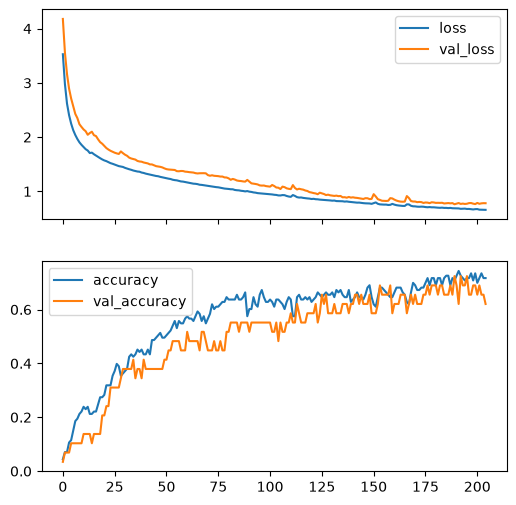

In [237]:
h = pd.DataFrame(training_history.history)
fig, (a, b) = plt.subplots(2, 1, figsize=(6, 6), sharex=True)
h[["loss", "val_loss"]].plot(ax=a)
h[["accuracy", "val_accuracy"]].plot(ax=b)

In [238]:
rpe_nn_model.evaluate(X_test, y_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - accuracy: 0.7241 - loss: 0.7621


[0.7621439099311829, 0.7241379022598267]

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 125ms/step


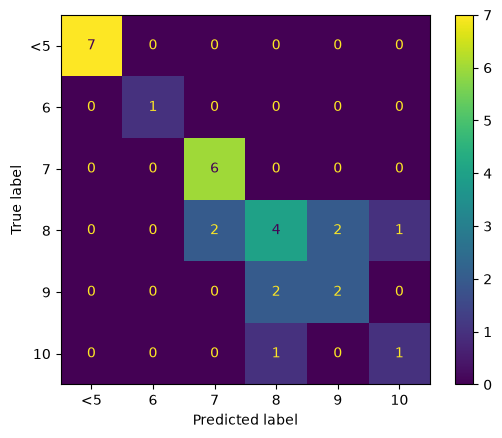

In [239]:
from sklearn.metrics import ConfusionMatrixDisplay

pred = rpe_nn_model.predict(X_test).argmax(axis=1)
ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["<5", 6, 7, 8, 9, 10])